# Module 17 — Exercises — Solutions

Exercises for **Module 17 — The Mathematics of Transformers**. They follow the order of the
[concept guide](README.md): embeddings and tied logits, scaled dot-product attention,
LayerNorm, the softmax Jacobian, the causal mask, parameter counting, sinusoidal and rotary
positions, the KV cache, a full pre-norm block, a conceptual diagnosis of the "temperature
replaces $\sqrt{d_k}$" fallacy, and a mini-project that trains a single-head causal
transformer with hand-derived gradients. Use only NumPy (plus `scipy.special.erf` for the GELU) and keep everything seeded.
A `softmax(z, axis=-1)` helper is defined in the setup cell.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True, linewidth=120)

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Embedding lookup and tied logits  `★☆☆`

Implement

* `embed(tokens, E)` — for an integer array `tokens` of shape `(n,)` and an embedding matrix
  `E` of shape `(V, d)`, return the `(n, d)` matrix of embeddings **as a one-hot matrix
  product** (`np.eye(V)[tokens] @ E`), not by indexing;
* `tied_logits(h, E)` — for a residual-stream vector `h` of shape `(d,)`, return the `(V,)`
  vector of logits $z = Eh$ under weight tying.

The hidden check asks for the largest next-token probability, $\max_v \operatorname{softmax}(Eh)_v$,
for the guide's five-token matrix and $h = (0.8, 0.2, 0.5)$.

In [3]:
def embed(tokens, E):
    one_hot = np.eye(E.shape[0])[tokens]        # (n, V)
    return one_hot @ E                          # (n, d)

def tied_logits(h, E):
    return E @ h                                # one dot product per vocabulary row

**Check your answer:**

In [4]:
_E = np.array([[1., 0., 0.5], [0., 1., 0.5], [-1., 0., 0.5], [0., -1., 0.5], [0.5, 0.5, 0.]])
try:
    got = embed(np.array([0, 1, 2]), _E)
except Exception:
    got = None
check_close('embed returns the rows of E for tokens 0,1,2', got, _E[[0, 1, 2]])
try:
    got_rep = embed(np.array([4, 4, 1]), _E)
except Exception:
    got_rep = None
check_close('repeated tokens give repeated rows', got_rep, _E[[4, 4, 1]])
try:
    z = tied_logits(np.array([0.8, 0.2, 0.5]), _E)
except Exception:
    z = None
check_close('logits for h = (0.8, 0.2, 0.5)', z, np.array([1.05, 0.45, -0.55, 0.05, 0.5]))
try:
    p_max = float(softmax(tied_logits(np.array([0.8, 0.2, 0.5]), _E)).max())
except Exception:
    p_max = None
check_hash('hidden: largest next-token probability (3 decimals)', p_max, 'c066c0678743d415')

✅ embed returns the rows of E for tokens 0,1,2
✅ repeated tokens give repeated rows
✅ logits for h = (0.8, 0.2, 0.5)
✅ hidden: largest next-token probability (3 decimals)


True

**Why this works**

A one-hot row $e_t^\top$ times $E$ picks out row $t$, so `np.eye(V)[tokens] @ E` equals
`E[tokens]` — but writing it as a product makes the gradient obvious: $\partial L/\partial E =
\text{one\_hot}^\top\,\partial L/\partial X$, non-zero only in the rows that occurred. Tied
logits are the dot products of $h$ with every embedding row, $z = Eh$, giving $(1.05, 0.45,
-0.55, 0.05, 0.5)$ and a top probability of $0.371$ for "the". A common slip is to write
`h @ E` (shape mismatch) or `E.T @ h`.

## Exercise 2 — Scaled dot-product attention  `★☆☆`

Implement `scaled_dot_product_attention(Q, K, V)` for `Q` of shape `(n_q, d_k)`, `K` of shape
`(n_k, d_k)` and `V` of shape `(n_k, d_v)`. Return the tuple `(output, P)` where
`P = softmax(Q K^T / sqrt(d_k))` is taken **row-wise** (one distribution per query) and
`output = P @ V`. Use only NumPy and the provided `softmax`.

In [5]:
def scaled_dot_product_attention(Q, K, V):
    d_k = Q.shape[-1]
    S = Q @ K.T / np.sqrt(d_k)
    P = softmax(S, axis=-1)
    return P @ V, P

**Check your answer:**

In [6]:
_Q = np.array([[1., 0.], [0., 1.], [1., 1.]]); _V = np.array([[2., 0.], [0., 2.], [1., 1.]])
try:
    out, P = scaled_dot_product_attention(_Q, _Q, _V)
except Exception:
    out, P = None, None
check_close('guide example: attention weights', P, np.array([[0.401112, 0.197776, 0.401112], [0.197776, 0.401112, 0.401112], [0.248255, 0.248255, 0.50349]]), tol=1e-5)
check_close('guide example: output rows', out, np.array([[1.203336, 0.796664], [0.796664, 1.203336], [1.0, 1.0]]), tol=1e-5)
_g = np.random.default_rng(3)
_K2 = _g.normal(size=(6, 4)); _V2 = _g.normal(size=(6, 3))
try:
    out_u, P_u = scaled_dot_product_attention(np.zeros((2, 4)), _K2, _V2)
except Exception:
    out_u, P_u = None, None
check('zero queries give uniform weights 1/6', P_u is not None and np.allclose(P_u, 1 / 6))
check_close('uniform weights give the mean of V', out_u, np.tile(_V2.mean(axis=0), (2, 1)))
try:
    _, P_s = scaled_dot_product_attention(_g.normal(size=(5, 4)), _K2, _V2)
    row_sums = P_s.sum(axis=1)
except Exception:
    row_sums = None
check_close('rows of P sum to one for random inputs', row_sums, np.ones(5))

✅ guide example: attention weights
✅ guide example: output rows
✅ zero queries give uniform weights 1/6
✅ uniform weights give the mean of V
✅ rows of P sum to one for random inputs


True

**Why this works**

The score matrix $S = QK^\top/\sqrt{d_k}$ has one row per query and one column per key; the
softmax must run along `axis=-1` so that each query's weights form a distribution. The output
row $o_i = \sum_j P_{ij}v_j$ is then a convex combination of value rows, which is why constant
scores give exactly the mean of $V$. The two classic bugs are the wrong softmax axis (columns
sum to one instead of rows) and dividing *after* the softmax, which does nothing useful.

## Exercise 3 — LayerNorm from scratch  `★☆☆`

Implement `layer_norm(X, gamma, beta, eps=1e-5)` for `X` of shape `(n, d)` (one token per
row), `gamma` and `beta` of shape `(d,)`:

$$\operatorname{LN}(x) = \gamma\odot\frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta,$$

with $\mu$ and $\sigma^2$ (the **biased** variance, `ddof=0`) computed **per row over the $d$
features**. Use only NumPy.

In [7]:
def layer_norm(X, gamma, beta, eps=1e-5):
    mu = X.mean(axis=-1, keepdims=True)
    var = X.var(axis=-1, keepdims=True)
    return gamma * (X - mu) / np.sqrt(var + eps) + beta

**Check your answer:**

In [8]:
_x = np.array([[2., 4., 6., 8.]])
try:
    got = layer_norm(_x, np.ones(4), np.zeros(4), eps=0.0)
except Exception:
    got = None
check_close('LN(2,4,6,8) with gamma=1, beta=0', got, np.array([[-1.341641, -0.447214, 0.447214, 1.341641]]), tol=1e-5)
try:
    got_inv = layer_norm(10 * _x + 100, np.ones(4), np.zeros(4), eps=0.0)
except Exception:
    got_inv = None
check_close('invariant to scaling and shifting the input', got_inv, got if got is not None else np.zeros(1))
_g = np.random.default_rng(5)
_X = _g.normal(size=(7, 16)) * 3 + 2; _gam = _g.normal(size=16); _bet = _g.normal(size=16)
try:
    out = layer_norm(_X, _gam, _bet)
    ref = _gam * (_X - _X.mean(1, keepdims=True)) / np.sqrt(_X.var(1, keepdims=True) + 1e-5) + _bet
except Exception:
    out, ref = None, np.zeros(1)
check_close('matches the formula with learned gamma, beta on a 7 x 16 batch', out, ref)
try:
    row_means = layer_norm(_X, np.ones(16), np.zeros(16)).mean(axis=1)
except Exception:
    row_means = None
check_close('every normalised row has mean 0', row_means, np.zeros(7), tol=1e-8)

✅ LN(2,4,6,8) with gamma=1, beta=0
✅ invariant to scaling and shifting the input
✅ matches the formula with learned gamma, beta on a 7 x 16 batch
✅ every normalised row has mean 0


True

**Why this works**

The statistics belong to one token: `axis=-1` with `keepdims=True` so that broadcasting
subtracts each row's own mean and divides by its own standard deviation. The output is
invariant to any affine rescaling of the input row, and $\gamma$, $\beta$ then put back a learned
scale and offset. Normalising along `axis=0` instead would mix tokens — batch-norm behaviour —
which breaks causality at inference and depends on which other sequences are in the batch.

## Exercise 4 — The softmax Jacobian, verified by finite differences  `★★☆`

Implement

* `softmax_jacobian(z)` — for logits `z` of shape `(n,)`, return the $n\times n$ matrix
  $J_{ij} = \partial p_i/\partial z_j = p_i(\delta_{ij} - p_j)$, i.e. $\operatorname{diag}(p) - pp^\top$;
* `finite_difference_jacobian(f, z, eps=1e-6)` — a generic central-difference Jacobian of a
  vector function `f` at `z`: column $j$ is $(f(z + \epsilon e_j) - f(z - \epsilon e_j))/(2\epsilon)$.

The hidden check asks for the largest absolute entry of the Jacobian at the saturated logits
$z = (6, 0, 0, 0)$, rounded to 4 decimals.

In [9]:
def softmax_jacobian(z):
    p = softmax(z)
    return np.diag(p) - np.outer(p, p)

def finite_difference_jacobian(f, z, eps=1e-6):
    n_out, n_in = f(z).size, z.size
    J = np.zeros((n_out, n_in))
    for j in range(n_in):
        e = np.zeros_like(z); e[j] = eps
        J[:, j] = (f(z + e) - f(z - e)) / (2 * eps)
    return J

**Check your answer:**

In [10]:
_z = np.log(np.array([0.7, 0.2, 0.1]))
try:
    J = softmax_jacobian(_z)
except Exception:
    J = None
check_close('J for p = (0.7, 0.2, 0.1)', J, np.array([[0.21, -0.14, -0.07], [-0.14, 0.16, -0.02], [-0.07, -0.02, 0.09]]), tol=1e-9)
check('rows of J sum to zero', J is not None and np.allclose(J.sum(axis=1), 0))
_g = np.random.default_rng(7); _z2 = _g.normal(size=6)
try:
    J_an = softmax_jacobian(_z2); J_fd = finite_difference_jacobian(softmax, _z2)
except Exception:
    J_an, J_fd = None, np.zeros(1)
check_close('analytic Jacobian matches finite differences on random logits', J_an, J_fd, tol=1e-6)
try:
    J_lin = finite_difference_jacobian(lambda v: np.array([[1., 2.], [3., 4.]]) @ v, np.array([0.3, -0.7]))
except Exception:
    J_lin = None
check_close('finite differences recover the matrix of a linear map', J_lin, np.array([[1., 2.], [3., 4.]]), tol=1e-6)
try:
    big = float(np.abs(softmax_jacobian(np.array([6.0, 0.0, 0.0, 0.0]))).max())
except Exception:
    big = None
check_hash('hidden: largest |J| entry at z = (6,0,0,0), 4 decimals', big, '5b81e92aa62bf5bd', decimals=4)

✅ J for p = (0.7, 0.2, 0.1)
✅ rows of J sum to zero
✅ analytic Jacobian matches finite differences on random logits
✅ finite differences recover the matrix of a linear map
✅ hidden: largest |J| entry at z = (6,0,0,0), 4 decimals


True

**Why this works**

For $i = j$ the quotient rule gives $p_i - p_i^2$, for $i \ne j$ it gives $-p_ip_j$; in matrix
form $\operatorname{diag}(p) - pp^\top$, which is symmetric with zero row sums because
$\sum_j p_j = 1$. Central differences have error $O(\epsilon^2)$, so with $\epsilon = 10^{-6}$ the
agreement is to about $10^{-9}$. At $z = (6, 0, 0, 0)$ the top probability is $0.993$ and the
largest Jacobian entry is $p_1(1-p_1) \approx 0.0074$ — the gradient wall that saturation builds.

## Exercise 5 — The causal mask and a no-leakage test  `★★☆`

Implement

* `causal_mask(n)` — an `(n, n)` boolean array that is `True` strictly **above** the diagonal
  (the forbidden future positions) and `False` elsewhere;
* `causal_attention(Q, K, V)` — scaled dot-product attention where the masked scores are set
  to `-np.inf` **before** the softmax (use `np.where`, never `mask * -np.inf`), returning
  `(output, P)`.

The checks verify that `P` is lower-triangular with rows summing to one, that no entry is NaN,
and — the real test — that changing the last token leaves every earlier output unchanged.

In [11]:
def causal_mask(n):
    return np.triu(np.ones((n, n), dtype=bool), k=1)      # True above the diagonal = forbidden

def causal_attention(Q, K, V):
    n = Q.shape[0]
    S = Q @ K.T / np.sqrt(Q.shape[-1])
    S = np.where(causal_mask(n), -np.inf, S)
    P = softmax(S, axis=-1)
    return P @ V, P

**Check your answer:**

In [12]:
try:
    m = causal_mask(4)
except Exception:
    m = None
check('causal_mask(4) is the strict upper triangle', m is not None and m.dtype == bool and np.array_equal(m, np.array([[0,1,1,1],[0,0,1,1],[0,0,0,1],[0,0,0,0]], dtype=bool)))
_g = np.random.default_rng(9)
_X = _g.normal(size=(6, 8)); _Wq, _Wk, _Wv = (_g.normal(size=(8, 4)) for _ in range(3))
try:
    out, P = causal_attention(_X @ _Wq, _X @ _Wk, _X @ _Wv)
except Exception:
    out, P = None, None
check('P is lower-triangular', P is not None and np.allclose(np.triu(P, 1), 0))
check('rows of P sum to one and contain no NaN', P is not None and not np.isnan(P).any() and np.allclose(P.sum(axis=1), 1))
check('position 0 attends only to itself', P is not None and np.isclose(P[0, 0], 1.0))
try:
    _X2 = _X.copy(); _X2[-1] += 5.0
    out2, _ = causal_attention(_X2 @ _Wq, _X2 @ _Wk, _X2 @ _Wv)
    changed = np.flatnonzero(np.abs(out2 - out).max(axis=1) > 1e-12)
except Exception:
    changed = None
check('editing the last token changes only the last output (no leakage)', changed is not None and np.array_equal(changed, np.array([5])))

✅ causal_mask(4) is the strict upper triangle
✅ P is lower-triangular
✅ rows of P sum to one and contain no NaN
✅ position 0 attends only to itself
✅ editing the last token changes only the last output (no leakage)


True

**Why this works**

`np.triu(np.ones((n, n), dtype=bool), k=1)` marks the strict upper triangle; `np.where(mask,
-np.inf, S)` replaces those scores so that $e^{-\infty} = 0$ after the (shift-invariant)
softmax. Multiplying a 0/1 mask by $-\infty$ instead produces `0 * -inf = nan` in the
*allowed* positions and poisons every row. The leakage test is the operational definition of
causality: because row $i$ of $P$ is zero beyond column $i$, output $i$ is a function of
tokens $0..i$ only, and perturbing token 5 can move only output 5.

## Exercise 6 — Counting the parameters of a transformer  `★★☆`

Implement `transformer_params(d, n_heads, d_ff, vocab, n_ctx, n_layer, tied=True)` returning
the tuple `(per_block, total)` of **integer** parameter counts for a GPT-2-style pre-norm
decoder with learned absolute positions:

* per block: $W_Q, W_K, W_V, W_O$ (each $d\times d$) with four bias vectors of length $d$;
  $W_1 \in \mathbb{R}^{d\times d_{\text{ff}}}$, $b_1$, $W_2 \in \mathbb{R}^{d_{\text{ff}}\times d}$, $b_2$;
  two LayerNorms with $\gamma, \beta \in \mathbb{R}^d$ each;
* total: `n_layer` blocks + token embedding ($V\times d$) + position embedding ($n_{\text{ctx}}\times d$)
  + a final LayerNorm ($2d$); if `tied=False`, add a separate unembedding matrix ($V\times d$).

Set `block_gpt2, total_gpt2 = transformer_params(768, 12, 3072, 50257, 1024, 12)`. The total
should be the famous "124M". Note that `n_heads` does not change the count — explain to
yourself why.

In [13]:
def transformer_params(d, n_heads, d_ff, vocab, n_ctx, n_layer, tied=True):
    attn = 4 * d * d + 4 * d                    # W_Q, W_K, W_V, W_O + four bias vectors
    mlp = d * d_ff + d_ff + d_ff * d + d        # W_1, b_1, W_2, b_2
    ln = 2 * (2 * d)                            # two LayerNorms (gamma, beta)
    block = attn + mlp + ln
    total = n_layer * block + vocab * d + n_ctx * d + 2 * d   # + token table, position table, final LN
    if not tied:
        total += vocab * d
    return block, total

block_gpt2, total_gpt2 = transformer_params(d=768, n_heads=12, d_ff=3072, vocab=50257, n_ctx=1024, n_layer=12)
print(f"GPT-2 small: {block_gpt2:,d} per block, {total_gpt2:,d} in total")

GPT-2 small: 7,087,872 per block, 124,439,808 in total


**Check your answer:**

In [14]:
check_hash('hidden: parameters per GPT-2-small block', block_gpt2 if isinstance(block_gpt2, (int, np.integer)) else None, 'c089ae38a7a2b769')
check_hash('hidden: total parameters of GPT-2 small', total_gpt2 if isinstance(total_gpt2, (int, np.integer)) else None, 'e2d00958fca3748a')
try:
    b_toy, t_toy = transformer_params(d=8, n_heads=2, d_ff=32, vocab=10, n_ctx=4, n_layer=1)
except Exception:
    b_toy, t_toy = None, None
check('toy config d=8, d_ff=32: block has 12*64 weights + 8*4 + 32 + 8 biases + 32 LN = 872', b_toy == 872)
check('toy config total = 872 + 80 + 32 + 16 = 1000', t_toy == 1000)
try:
    _, t_untied = transformer_params(d=8, n_heads=2, d_ff=32, vocab=10, n_ctx=4, n_layer=1, tied=False)
except Exception:
    t_untied = None
check('untied unembedding adds vocab * d', t_untied == 1080)
try:
    _, t_xl = transformer_params(d=1600, n_heads=25, d_ff=6400, vocab=50257, n_ctx=1024, n_layer=48)
except Exception:
    t_xl = None
check_hash('hidden: GPT-2 XL total (d=1600, 48 layers)', t_xl if isinstance(t_xl, (int, np.integer)) else None, '5978614fc49fe0e5')

✅ hidden: parameters per GPT-2-small block
✅ hidden: total parameters of GPT-2 small
✅ toy config d=8, d_ff=32: block has 12*64 weights + 8*4 + 32 + 8 biases + 32 LN = 872
✅ toy config total = 872 + 80 + 32 + 16 = 1000
✅ untied unembedding adds vocab * d
✅ hidden: GPT-2 XL total (d=1600, 48 layers)


True

**Why this works**

The weights per block are $4d^2$ (attention) $+ 2d\,d_{\text{ff}} = 8d^2$ (feed-forward with
$d_{\text{ff}} = 4d$), i.e. $12d^2 = 7{,}077{,}888$ for $d = 768$; biases ($4d + d_{\text{ff}} + d$)
and two LayerNorms ($4d$) add $9{,}984$, giving $7{,}087{,}872$ per block. Twelve blocks plus the
$50{,}257\times768$ token table, the $1024\times768$ position table and the final LayerNorm give
$124{,}439{,}808$. The head count never appears: splitting $W_Q$ into $h$ slices of width $d/h$
does not change its size. GPT-2 XL by the same recipe comes to about $1.56$ billion.

## Exercise 7 — Sinusoidal positional encodings and the relative-shift matrix  `★★☆`

Implement

* `sinusoidal_pe(n_pos, d)` — the `(n_pos, d)` table with $PE(pos, 2i) = \sin(pos\,\omega_i)$,
  $PE(pos, 2i+1) = \cos(pos\,\omega_i)$ and $\omega_i = 10000^{-2i/d}$ for $i = 0, \dots, d/2-1$
  (`d` is even; sines in the even columns, cosines in the odd columns);
* `shift_matrix(k, d)` — the `(d, d)` block-diagonal matrix $R_k$ with $2\times2$ blocks
  $\begin{pmatrix}\cos k\omega_i & \sin k\omega_i\\ -\sin k\omega_i & \cos k\omega_i\end{pmatrix}$,
  so that $PE(pos + k) = R_k\,PE(pos)$ for **every** `pos`.

The checks verify the guide's $d = 4$ values and the shift identity for $k = 5$ on a $d = 16$ table.

In [15]:
def sinusoidal_pe(n_pos, d):
    pos = np.arange(n_pos)[:, None]
    i = np.arange(d // 2)[None, :]
    omega = 10000.0 ** (-2 * i / d)
    pe = np.zeros((n_pos, d))
    pe[:, 0::2] = np.sin(pos * omega)
    pe[:, 1::2] = np.cos(pos * omega)
    return pe

def shift_matrix(k, d):
    omega = 10000.0 ** (-2 * np.arange(d // 2) / d)
    R = np.zeros((d, d))
    for i, w in enumerate(omega):
        c, s = np.cos(k * w), np.sin(k * w)
        R[2 * i:2 * i + 2, 2 * i:2 * i + 2] = [[c, s], [-s, c]]
    return R

**Check your answer:**

In [16]:
try:
    pe4 = sinusoidal_pe(3, 4)
except Exception:
    pe4 = None
check_close('PE for d = 4, positions 0..2', pe4, np.array([[0., 1., 0., 1.], [0.841471, 0.540302, 0.01, 0.99995], [0.909297, -0.416147, 0.019999, 0.9998]]), tol=1e-5)
try:
    pe = sinusoidal_pe(40, 16); R5 = shift_matrix(5, 16)
    shifted = pe[:-5] @ R5.T          # row pos -> R_5 PE(pos)
except Exception:
    pe, R5, shifted = None, None, None
check('shapes (40, 16) and (16, 16)', pe is not None and pe.shape == (40, 16) and R5.shape == (16, 16))
check_close('PE(pos + 5) == R_5 PE(pos) for all pos', shifted, pe[5:] if pe is not None else np.zeros(1), tol=1e-9)
check('R_5 is orthogonal', R5 is not None and np.allclose(R5.T @ R5, np.eye(16)))
try:
    row_norms = np.linalg.norm(sinusoidal_pe(10, 8), axis=1)
except Exception:
    row_norms = None
check_close('every row of PE has norm sqrt(d/2)', row_norms, np.full(10, 2.0))

✅ PE for d = 4, positions 0..2
✅ shapes (40, 16) and (16, 16)
✅ PE(pos + 5) == R_5 PE(pos) for all pos
✅ R_5 is orthogonal
✅ every row of PE has norm sqrt(d/2)


True

**Why this works**

Each pair $(\sin(pos\,\omega_i), \cos(pos\,\omega_i))$ is a point on the unit circle at angle
$pos\,\omega_i$, so advancing by $k$ positions is a rotation by $k\omega_i$ — the angle-addition
formulas written as a $2\times2$ matrix. Because the rotation depends on $k$ but not on $pos$,
a learned $W_Q$, $W_K$ can match "the token $k$ steps back" with a position-independent linear
map. Every row has norm $\sqrt{d/2}$ since each pair contributes $\sin^2 + \cos^2 = 1$. A common
error is to use $\omega_i = 10000^{-i/d}$ (forgetting the factor 2) or to interleave the pairs
differently from the matrix — either breaks the shift identity.

## Exercise 8 — Rotary position embeddings (RoPE)  `★★☆`

Implement

* `rope(x, positions, base=10000.0)` — for `x` of shape `(n, d)` (`d` even) and integer
  `positions` of shape `(n,)`, rotate each coordinate pair $(x_{2i}, x_{2i+1})$ of row $m$ by
  the angle $m\,\theta_i$ with $\theta_i = \text{base}^{-2i/d}$:
  $(x_{2i}\cos - x_{2i+1}\sin,\ x_{2i}\sin + x_{2i+1}\cos)$;
* `rope_scores(Q, K, positions)` — the score matrix $\operatorname{rope}(Q)\operatorname{rope}(K)^\top/\sqrt{d}$.

The checks verify the $2$-D rotation by hand, that norms are preserved, and the defining
property: shifting **all** positions by the same amount leaves every score unchanged, while a
different offset changes them.

In [17]:
def rope(x, positions, base=10000.0):
    n_pos, d = x.shape
    theta = base ** (-2 * np.arange(d // 2) / d)
    ang = positions[:, None] * theta[None, :]
    c, s = np.cos(ang), np.sin(ang)
    x1, x2 = x[:, 0::2], x[:, 1::2]
    out = np.empty_like(x)
    out[:, 0::2] = x1 * c - x2 * s
    out[:, 1::2] = x1 * s + x2 * c
    return out

def rope_scores(Q, K, positions):
    return rope(Q, positions) @ rope(K, positions).T / np.sqrt(Q.shape[-1])

**Check your answer:**

In [18]:
try:
    r = rope(np.array([[1., 0.]]), np.array([3]))        # d = 2: theta_0 = 1, angle = 3 rad
except Exception:
    r = None
check_close('d = 2, position 3 rotates (1,0) to (cos 3, sin 3)', r, np.array([[np.cos(3.0), np.sin(3.0)]]))
_g = np.random.default_rng(11)
_Q = _g.normal(size=(5, 8)); _K = _g.normal(size=(5, 8)); _pos = np.arange(5)
try:
    norms_ok = np.allclose(np.linalg.norm(rope(_Q, _pos), axis=1), np.linalg.norm(_Q, axis=1))
except Exception:
    norms_ok = False
check('rotation preserves the norm of every row', norms_ok)
try:
    S0 = rope_scores(_Q, _K, _pos); S_shift = rope_scores(_Q, _K, _pos + 1000)
except Exception:
    S0, S_shift = None, np.zeros(1)
check_close('shifting all positions by 1000 leaves the scores unchanged', S0, S_shift, tol=1e-8)
try:
    S_other = rope_scores(_Q, _K, np.array([0, 2, 4, 6, 8]))
    differs = not np.allclose(S0, S_other)
except Exception:
    differs = False
check('different relative offsets give different scores', differs)
try:
    same_pos = rope_scores(_Q, _K, np.zeros(5, dtype=int))
except Exception:
    same_pos = None
check_close('all positions equal -> plain scaled dot products', same_pos, _Q @ _K.T / np.sqrt(8))

✅ d = 2, position 3 rotates (1,0) to (cos 3, sin 3)
✅ rotation preserves the norm of every row
✅ shifting all positions by 1000 leaves the scores unchanged
✅ different relative offsets give different scores
✅ all positions equal -> plain scaled dot products


True

**Why this works**

Rotating $q$ by $m\theta$ and $k$ by $n\theta$ gives $q_m^\top k_n = q^\top R(m\theta)^\top R(n\theta)k
= q^\top R((n-m)\theta)k$, so only the offset $n - m$ survives — adding $1000$ to every position
changes nothing, while spacing the positions differently does. Rotations are orthogonal, so
norms are preserved and at position $0$ (angle $0$) RoPE is the identity. Implementations
usually write the rotation as `x * cos + rotate_half(x) * sin`; the pairing convention differs
between codebases (adjacent pairs here, first-half/second-half in Llama) but the mathematics is
the same.

## Exercise 9 — KV-cache memory arithmetic  `★★☆`

Implement

* `kv_cache_bytes(n_layer, n_tokens, n_kv_heads, d_head, bytes_per_number=2)` — the bytes
  needed to cache keys **and** values for one sequence: $2 \cdot L \cdot t \cdot h_{kv} \cdot d_{\text{head}} \cdot \text{bytes}$
  (return an `int`);
* `max_sequences(gpu_bytes, weight_bytes, n_layer, n_tokens, n_kv_heads, d_head, bytes_per_number=2)` —
  how many full-length sequences fit in the memory left after the weights (floor division, `int`).

Then set `cache_7b = kv_cache_bytes(32, 8192, 32, 128)` (should be exactly 4 GiB) and
`cache_gqa = kv_cache_bytes(48, 32768, 8, 128)` (hidden). The second hidden check calls
`max_sequences` with an 80 GB GPU ($80\times10^9$ bytes), a 6.74B-parameter model in fp16, and
a 4096-token context with 8 KV heads of width 128.

In [19]:
def kv_cache_bytes(n_layer, n_tokens, n_kv_heads, d_head, bytes_per_number=2):
    return 2 * n_layer * n_tokens * n_kv_heads * d_head * bytes_per_number

def max_sequences(gpu_bytes, weight_bytes, n_layer, n_tokens, n_kv_heads, d_head, bytes_per_number=2):
    per_seq = kv_cache_bytes(n_layer, n_tokens, n_kv_heads, d_head, bytes_per_number)
    return int((gpu_bytes - weight_bytes) // per_seq)

cache_7b = kv_cache_bytes(n_layer=32, n_tokens=8192, n_kv_heads=32, d_head=128)
cache_gqa = kv_cache_bytes(n_layer=48, n_tokens=32768, n_kv_heads=8, d_head=128)
print(f"7B-class, 8k context, fp16: {cache_7b / 2**30:.2f} GiB;  48-layer GQA model at 32k: {cache_gqa / 2**30:.2f} GiB")

7B-class, 8k context, fp16: 4.00 GiB;  48-layer GQA model at 32k: 6.00 GiB


**Check your answer:**

In [20]:
check('cache_7b is exactly 4 GiB = 2**32 bytes', cache_7b == 2 ** 32)
try:
    gpt2 = kv_cache_bytes(12, 1024, 12, 64)
except Exception:
    gpt2 = None
check('GPT-2 small at 1024 tokens: 36 MiB', gpt2 == 36 * 2 ** 20)
try:
    int8 = kv_cache_bytes(32, 8192, 32, 128, bytes_per_number=1)
except Exception:
    int8 = None
check('an 8-bit cache halves the bytes', int8 == 2 ** 31)
check_hash('hidden: cache_gqa (48 layers, 32k tokens, 8 KV heads of 128, fp16)', cache_gqa if isinstance(cache_gqa, (int, np.integer)) else None, 'f48ddfabd33ac046')
try:
    n_seq = max_sequences(80 * 10**9, 2 * 6_740_000_000, 32, 4096, 8, 128)
except Exception:
    n_seq = None
check_hash('hidden: sequences that fit next to a 6.74B fp16 model on 80 GB', n_seq if isinstance(n_seq, (int, np.integer)) else None, 'a665a45920422f9d')

✅ cache_7b is exactly 4 GiB = 2**32 bytes
✅ GPT-2 small at 1024 tokens: 36 MiB
✅ an 8-bit cache halves the bytes
✅ hidden: cache_gqa (48 layers, 32k tokens, 8 KV heads of 128, fp16)
✅ hidden: sequences that fit next to a 6.74B fp16 model on 80 GB


True

**Why this works**

Each layer stores one key vector and one value vector per token, each of length
$h_{kv}d_{\text{head}}$ ($= d$ for ordinary multi-head attention), hence the factor $2$. For
$L = 32$, $t = 8192$, $d = 4096$ in fp16: $2\cdot32\cdot8192\cdot4096\cdot2 = 2^{32}$ bytes, i.e.
exactly $4$ GiB. Grouped-query attention shrinks $h_{kv}$ and therefore the cache
proportionally, which is why a 48-layer GQA model at 32k context needs only $6$ GiB. For the
serving question, $80\times10^9 - 13.48\times10^9 = 66.5$ GB remain, and each 4096-token sequence
with 8 KV heads costs $2\cdot32\cdot4096\cdot1024\cdot2 = 512$ MiB, so $123$ sequences fit —
the cache, not the weights, sets the batch size.

## Exercise 10 — A complete pre-norm transformer block  `★★★`

Using your `layer_norm` from Exercise 3 and the provided `softmax`, implement

* `gelu(u)` $= u\,\Phi(u) = \tfrac12 u\,(1 + \operatorname{erf}(u/\sqrt2))$ (use `scipy.special.erf`, imported in the setup);
* `multi_head_attention(X, W_Q, W_K, W_V, W_O, n_heads, mask=None)` — split the `(n, d)`
  projections into `n_heads` heads of width `d // n_heads`, run scaled dot-product attention
  per head (scale by $\sqrt{d_{\text{head}}}$, apply the boolean `mask` with `-np.inf` if given),
  concatenate, and multiply by `W_O`; return the `(n, d)` output;
* `transformer_block(X, p, n_heads, mask=None)` — the pre-norm block
  $X \leftarrow X + \operatorname{MHA}(\operatorname{LN}_1 X)$, then
  $X \leftarrow X + \operatorname{GELU}(\operatorname{LN}_2(X)\,W_1 + b_{f1})\,W_2 + b_{f2}$,
  with parameters in the dict `p` under the keys
  `W_Q, W_K, W_V, W_O, W_1, bf1, W_2, bf2, g1, b1, g2, b2` (`g`/`b` are the LayerNorm gains and biases).

The checks compare against a reference on random weights, verify that one head equals plain
attention, that the block is causal when masked, and that zero attention/FFN output weights
make the block the identity.

In [21]:
def gelu(u):
    return 0.5 * u * (1.0 + erf(u / np.sqrt(2.0)))

def multi_head_attention(X, W_Q, W_K, W_V, W_O, n_heads, mask=None):
    n, d = X.shape
    d_head = d // n_heads
    split = lambda M: M.reshape(n, n_heads, d_head).transpose(1, 0, 2)
    Qh, Kh, Vh = split(X @ W_Q), split(X @ W_K), split(X @ W_V)
    S = Qh @ Kh.transpose(0, 2, 1) / np.sqrt(d_head)
    if mask is not None:
        S = np.where(mask[None], -np.inf, S)
    P = softmax(S, axis=-1)
    return (P @ Vh).transpose(1, 0, 2).reshape(n, d) @ W_O

def transformer_block(X, p, n_heads, mask=None):
    h1 = layer_norm(X, p["g1"], p["b1"])
    X = X + multi_head_attention(h1, p["W_Q"], p["W_K"], p["W_V"], p["W_O"], n_heads, mask)
    h2 = layer_norm(X, p["g2"], p["b2"])
    return X + gelu(h2 @ p["W_1"] + p["bf1"]) @ p["W_2"] + p["bf2"]

**Check your answer:**

In [22]:
try:
    g_vals = gelu(np.array([-1., 0., 1., 2.]))
except Exception:
    g_vals = None
check_close('GELU(-1, 0, 1, 2)', g_vals, np.array([-0.158655, 0.0, 0.841345, 1.9545]), tol=1e-5)
_g = np.random.default_rng(17)
_n, _d, _h, _dff = 6, 16, 4, 64
_X = _g.normal(size=(_n, _d))
_p = dict(W_Q=_g.normal(size=(_d, _d)) / 4, W_K=_g.normal(size=(_d, _d)) / 4, W_V=_g.normal(size=(_d, _d)) / 4, W_O=_g.normal(size=(_d, _d)) / 4,
          W_1=_g.normal(size=(_d, _dff)) / 4, bf1=_g.normal(size=_dff) * 0.1, W_2=_g.normal(size=(_dff, _d)) / 8, bf2=_g.normal(size=_d) * 0.1,
          g1=1 + 0.1 * _g.normal(size=_d), b1=0.1 * _g.normal(size=_d), g2=1 + 0.1 * _g.normal(size=_d), b2=0.1 * _g.normal(size=_d))
def _ref_mha(X, p, n_heads, mask):
    n, d = X.shape; dh = d // n_heads; outs = []
    for i in range(n_heads):
        sl = slice(i * dh, (i + 1) * dh)
        S = (X @ p["W_Q"][:, sl]) @ (X @ p["W_K"][:, sl]).T / np.sqrt(dh)
        if mask is not None:
            S = np.where(mask, -np.inf, S)
        outs.append(softmax(S, axis=-1) @ (X @ p["W_V"][:, sl]))
    return np.concatenate(outs, axis=1) @ p["W_O"]
def _ref_block(X, p, n_heads, mask):
    ln = lambda Z, g, b: g * (Z - Z.mean(-1, keepdims=True)) / np.sqrt(Z.var(-1, keepdims=True) + 1e-5) + b
    X = X + _ref_mha(ln(X, p["g1"], p["b1"]), p, n_heads, mask)
    H = ln(X, p["g2"], p["b2"]) @ p["W_1"] + p["bf1"]
    return X + 0.5 * H * (1 + erf(H / np.sqrt(2))) @ p["W_2"] + p["bf2"]
try:
    mha = multi_head_attention(_X, _p["W_Q"], _p["W_K"], _p["W_V"], _p["W_O"], _h)
except Exception:
    mha = None
check_close('multi-head attention matches a per-head loop reference (4 heads)', mha, _ref_mha(_X, _p, _h, None), tol=1e-8)
try:
    one_head = multi_head_attention(_X, _p["W_Q"], _p["W_K"], _p["W_V"], _p["W_O"], 1)
    plain = softmax((_X @ _p["W_Q"]) @ (_X @ _p["W_K"]).T / np.sqrt(_d), axis=-1) @ (_X @ _p["W_V"]) @ _p["W_O"]
except Exception:
    one_head, plain = None, np.zeros(1)
check_close('one head equals plain attention times W_O', one_head, plain, tol=1e-8)
_mask = np.triu(np.ones((_n, _n), dtype=bool), 1)
try:
    blk = transformer_block(_X, _p, _h, _mask)
except Exception:
    blk = None
check_close('causal pre-norm block matches the reference', blk, _ref_block(_X, _p, _h, _mask), tol=1e-8)
try:
    _X2 = _X.copy(); _X2[-1] += 3.0
    blk2 = transformer_block(_X2, _p, _h, _mask)
    causal_ok = np.allclose(blk2[:-1], blk[:-1]) and not np.allclose(blk2[-1], blk[-1])
except Exception:
    causal_ok = False
check('masked block is causal: editing the last token changes only the last row', causal_ok)
try:
    _p0 = dict(_p); _p0["W_O"] = np.zeros((_d, _d)); _p0["W_2"] = np.zeros((_dff, _d)); _p0["bf2"] = np.zeros(_d)
    ident = transformer_block(_X, _p0, _h)
except Exception:
    ident = None
check_close('zero output weights make the block the identity (residual path)', ident, _X)

✅ GELU(-1, 0, 1, 2)
✅ multi-head attention matches a per-head loop reference (4 heads)
✅ one head equals plain attention times W_O
✅ causal pre-norm block matches the reference
✅ masked block is causal: editing the last token changes only the last row
✅ zero output weights make the block the identity (residual path)


True

**Why this works**

Reshaping the `(n, d)` projections to `(n, h, d_head)` and moving the head axis first lets one
batched matmul compute all heads' scores at once; the heads are concatenated by reversing the
reshape before $W_O$. The pre-norm block normalises *before* each sub-layer and adds the result
to the untouched residual stream — which is why zeroing $W_O$, $W_2$ and $b_{f2}$ reduces the
block to the identity, and why gradients always have a clean path through deep stacks.
Causality is inherited from the mask alone: LayerNorm and the FFN act on each row separately.
Frequent errors: scaling by $\sqrt{d}$ instead of $\sqrt{d_{\text{head}}}$, normalising after the
residual add (post-norm), and transposing the wrong axes when re-merging heads.

## Exercise 11 — Diagnose: 'temperature makes the sqrt(d_k) unnecessary'  `★★☆`

A colleague argues: "Dividing attention scores by $\sqrt{d_k}$ is just a fixed temperature, and
the model can learn any temperature it likes by scaling $W_Q$ — so the constant is cosmetic and I
removed it from my implementation with $d_k = 128$." Training is now far slower and sometimes
diverges.

Explain what is right and what is wrong in the argument. Use the variance of the scores at
initialisation, the softmax Jacobian, and the size of the gradient that reaches $W_Q$ and $W_K$
to say *why* the learning dynamics changed even though the function class did not.

**Answer**

The colleague is right that the function class is unchanged: $\operatorname{softmax}(QK^\top/\sqrt{d_k})$
with $W_Q$ equals $\operatorname{softmax}(QK^\top)$ with $W_Q/\sqrt{d_k}$, so any attention pattern
reachable with the constant is reachable without it. The argument fails on the *dynamics*. At
initialisation the components of $q$ and $k$ have roughly unit variance, so a raw score
$q^\top k$ has variance $d_k = 128$ and standard deviation $\approx 11$; the softmax of a row
whose entries differ by about $11$ is essentially one-hot. The softmax Jacobian
$\operatorname{diag}(p) - pp^\top$ then has entries of order $p_{\max}(1 - p_{\max}) \approx e^{-11}$,
and the gradient reaching the scores — and through them $W_Q$ and $W_K$ — is multiplied by that
factor. The weights that would have to shrink by $\sqrt{128}$ to fix the problem receive
almost no gradient to do so, so training stalls; where some rows are not saturated the gradients
are large and uneven, which produces the instability. The $\sqrt{d_k}$ places the model, *at the
start*, in the regime where gradients flow; a "learned temperature" can only be learned if the
gradient signal exists. The same reasoning is why initialisation scales (Module 16) matter even
though they, too, are "just a reparametrisation".

## Exercise 12 — Mini-project: train a single-head causal transformer with hand-derived gradients  `★★★`

Build the smallest possible language model — token embedding $E$ + learned position table $P$,
one causal single-head attention layer ($W_Q, W_K, W_V$, no $W_O$), and an unembedding $W_U$ —
and train it with **gradients you derive yourself** (no autograd) on sequences that repeat a
random 5-token pattern. The model can only solve the task by learning to attend exactly 4
positions back and copy, so the attention pattern it learns is checkable.

1. Forward pass for a batch `tok` of shape `(B, n)`: $X = E[\text{tok}] + P$;
   $Q, K, V = XW_Q, XW_K, XW_V$; $S = QK^\top/\sqrt{d}$ with the causal mask; $P_{\text{att}} = \operatorname{softmax}(S)$;
   $O = P_{\text{att}}V$; logits $= OW_U$; loss = mean cross-entropy over the **scored** positions
   (`SCORED`, where the next token is predictable).
2. Backward pass by hand: $\partial\text{logits} = (p - y)/m$ on scored positions (Module 16);
   $\partial W_U = O^\top\partial\text{logits}$; $\partial O = \partial\text{logits}\,W_U^\top$;
   $\partial V = P_{\text{att}}^\top\partial O$; $\partial P_{\text{att}} = \partial O\,V^\top$;
   $\partial S = P_{\text{att}}\odot(\partial P_{\text{att}} - \operatorname{rowsum}(\partial P_{\text{att}}\odot P_{\text{att}}))$;
   $\partial Q = \partial S\,K/\sqrt d$; $\partial K = \partial S^\top Q/\sqrt d$; then
   $\partial W_Q = X^\top\partial Q$ etc., $\partial X = \partial Q\,W_Q^\top + \partial K\,W_K^\top + \partial V\,W_V^\top$,
   $\partial P = \sum_{\text{batch}}\partial X$, and $\partial E$ by scattering $\partial X$ into the rows of the tokens used (`np.add.at`).
3. **Gradient-check** every parameter against central finite differences before training.
4. Train with Adam (Module 05) for about 1000 steps, batch 16, learning rate $10^{-2}$; plot
   the loss; report next-token accuracy on fresh sequences.
5. Plot the learned attention matrix for one sequence and verify that each scored query puts
   most of its weight on a position `PERIOD - 1 = 4` steps back — or 9 or 14 steps back, which
   carry the same token in a period-5 sequence. Measure the total weight on those positions.

Keep the run under 60 seconds (the reference takes a few seconds). The cell below defines the
task and the data generator.

**Rubric — you have mastered this when you can:**

- Every analytic gradient matches central finite differences to a relative error below $10^{-5}$.
- The training loss falls from about $\ln 8 \approx 2.08$ to below $0.05$ and the next-token
  accuracy on fresh sequences is above 0.98.
- The learned attention of scored positions concentrates (total weight $> 0.8$) on the positions
  $4, 9, 14, \dots$ steps back — all congruent to $i - 4 \pmod 5$ and all carrying the right
  token; the plot has a title, axis labels and a colour bar. You can explain why the model is
  free to pick any of them and why it may pick different ones at different positions.
- You can explain in two sentences why the model needs the position table to solve this task
  (a bare attention layer is permutation-equivariant and cannot say "4 steps back"), and
  predict what happens if you remove `P` — then test it.
- You can point to the line in your backward pass that implements the softmax Jacobian and
  explain why it is $P\odot(\cdot - \text{rowsum})$ rather than a full $n\times n\times n$ tensor.
- (Bonus) Replace the learned position table by RoPE on $Q$ and $K$ (Exercise 8) and confirm the
  model still learns the offset-4 pattern.

**Solution sketch**

Store intermediates in the forward pass and walk them backwards. The only non-trivial step is the
softmax Jacobian applied to each attention row, `dS = P_att * (dP - (dP * P_att).sum(-1, keepdims=True))`,
and the scatter-add into $E$ with `np.add.at(dE, tok.ravel(), dX.reshape(-1, d))`. The gradient
check agrees to about $10^{-8}$ relative error; Adam at learning rate $10^{-2}$ drives the loss
below $10^{-3}$ within a few hundred steps and the accuracy on fresh sequences to $1.0$. The
attention heat-map shows diagonal bands at offsets 4, 9 and 14: query position $i$ attends to a
key $i - 4$, $i - 9$ or $i - 14$, whose *next* token is in every case the target — the task does
not distinguish between these copy sources, so the model settles on whichever the optimiser
reached first for each query position, and the total weight on the valid set is close to 1.
Without the position table the loss plateaus near $\ln 8$ — the model can see which tokens are
present but not where.

example input : [2 4 3 6 5 2 4 3 6 5 2 4 3 6 5 2 4 3 6 5]
example target: [4 3 6 5 2 4 3 6 5 2 4 3 6 5 2 4 3 6 5 2]
positions scored: [ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
initial loss 2.0780 (ln 8 = 2.0794)
gradient check: worst relative error over 18 random entries = 3.24e-06


step  200: loss 0.0002, batch accuracy 1.000


step  400: loss 0.0001, batch accuracy 1.000


step  600: loss 0.0000, batch accuracy 1.000


step  800: loss 0.0000, batch accuracy 1.000


step 1000: loss 0.0000, batch accuracy 1.000
next-token accuracy on 200 fresh sequences: 1.000


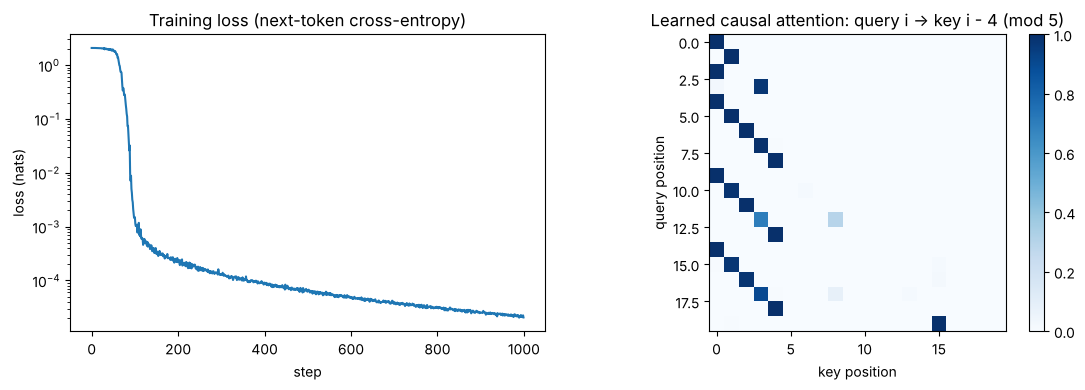

argmax offset (query - key) for scored positions: [ 4  4  4  4  4  9  9  9  9  9 14 14 14 14 14  4] -> all congruent to 4 mod 5: True
total attention weight on valid copy sources (offsets 4, 9, 14): mean 0.996, min 0.980


In [23]:
# ---- toy task: sequences that repeat a random 5-token pattern; the model must learn "copy the token 4 steps back" ----
V_TOK, PERIOD, N_POS, D_MODEL = 8, 5, 20, 16
g = np.random.default_rng(0)

def make_batch(batch_size, g):
    pats = np.stack([g.permutation(V_TOK)[:PERIOD] for _ in range(batch_size)])     # a fresh pattern per sequence
    seq = np.concatenate([pats] * (N_POS // PERIOD + 2), axis=1)[:, :N_POS + 1]
    return seq[:, :-1], seq[:, 1:]                                                    # inputs (B, n), targets (B, n)

SCORED = np.arange(N_POS) >= PERIOD - 1       # from position 4 on, the next token is determined by the past
MASK = np.triu(np.ones((N_POS, N_POS), dtype=bool), 1)
tok, tgt = make_batch(2, g)
print("example input :", tok[0]); print("example target:", tgt[0]); print("positions scored:", np.flatnonzero(SCORED))


def init_params(g, scale=0.1):
    return dict(E=scale * g.normal(size=(V_TOK, D_MODEL)), P=scale * g.normal(size=(N_POS, D_MODEL)),
                W_Q=scale * g.normal(size=(D_MODEL, D_MODEL)), W_K=scale * g.normal(size=(D_MODEL, D_MODEL)),
                W_V=scale * g.normal(size=(D_MODEL, D_MODEL)), W_U=scale * g.normal(size=(D_MODEL, V_TOK)))

def forward(p, tok):
    X = p["E"][tok] + p["P"][None, :, :]                       # (B, n, d)
    Q, K, Vv = X @ p["W_Q"], X @ p["W_K"], X @ p["W_V"]
    S = Q @ K.transpose(0, 2, 1) / np.sqrt(D_MODEL)
    S = np.where(MASK[None], -np.inf, S)
    P_att = softmax(S, axis=-1)
    O = P_att @ Vv
    return dict(X=X, Q=Q, K=K, V=Vv, P_att=P_att, O=O, logits=O @ p["W_U"])

def loss_and_grads(p, tok, tgt):
    c = forward(p, tok)
    B = tok.shape[0]
    probs = softmax(c["logits"], axis=-1)                     # (B, n, V)
    Y = np.zeros_like(probs); Y[np.arange(B)[:, None], np.arange(N_POS)[None, :], tgt] = 1.0
    w = SCORED[None, :, None].astype(float); m = B * SCORED.sum()
    loss = -(w * Y * np.log(probs + 1e-12)).sum() / m
    dlogits = w * (probs - Y) / m                             # softmax + cross-entropy: (p - y) / m
    gr = {}
    gr["W_U"] = np.einsum("bnd,bnv->dv", c["O"], dlogits)
    dO = dlogits @ p["W_U"].T
    dV = c["P_att"].transpose(0, 2, 1) @ dO
    dP = dO @ c["V"].transpose(0, 2, 1)
    dS = c["P_att"] * (dP - (dP * c["P_att"]).sum(axis=-1, keepdims=True))   # softmax Jacobian, row by row
    dQ = dS @ c["K"] / np.sqrt(D_MODEL)
    dK = dS.transpose(0, 2, 1) @ c["Q"] / np.sqrt(D_MODEL)
    X = c["X"]
    gr["W_Q"] = np.einsum("bnd,bne->de", X, dQ); gr["W_K"] = np.einsum("bnd,bne->de", X, dK); gr["W_V"] = np.einsum("bnd,bne->de", X, dV)
    dX = dQ @ p["W_Q"].T + dK @ p["W_K"].T + dV @ p["W_V"].T
    gr["P"] = dX.sum(axis=0)
    gr["E"] = np.zeros_like(p["E"]); np.add.at(gr["E"], tok.ravel(), dX.reshape(-1, D_MODEL))
    acc = float((probs.argmax(-1) == tgt)[:, SCORED].mean())
    return loss, gr, acc

# ---- gradient check
params = init_params(g); tok, tgt = make_batch(2, g)
loss0, grads, _ = loss_and_grads(params, tok, tgt)
print(f"initial loss {loss0:.4f} (ln 8 = {np.log(8):.4f})")
worst = 0.0
for name in params:
    for _ in range(3):
        idx = tuple(g.integers(0, s) for s in params[name].shape)
        old = params[name][idx]; eps = 1e-5
        params[name][idx] = old + eps; lp = loss_and_grads(params, tok, tgt)[0]
        params[name][idx] = old - eps; lm = loss_and_grads(params, tok, tgt)[0]
        params[name][idx] = old
        fd = (lp - lm) / (2 * eps)
        worst = max(worst, abs(grads[name][idx] - fd) / max(1e-8, abs(fd)))
print(f"gradient check: worst relative error over 18 random entries = {worst:.2e}")

# ---- Adam
params = init_params(g)
m1 = {k: np.zeros_like(v) for k, v in params.items()}; m2 = {k: np.zeros_like(v) for k, v in params.items()}
lr, b1, b2, eps_adam = 1e-2, 0.9, 0.999, 1e-8
history = []
for step in range(1, 1001):
    tok, tgt = make_batch(16, g)
    loss, grads, acc = loss_and_grads(params, tok, tgt)
    for k in params:
        m1[k] = b1 * m1[k] + (1 - b1) * grads[k]; m2[k] = b2 * m2[k] + (1 - b2) * grads[k] ** 2
        params[k] -= lr * (m1[k] / (1 - b1 ** step)) / (np.sqrt(m2[k] / (1 - b2 ** step)) + eps_adam)
    history.append(loss)
    if step % 200 == 0:
        print(f"step {step:4d}: loss {loss:.4f}, batch accuracy {acc:.3f}")

tok_test, tgt_test = make_batch(200, np.random.default_rng(123))
_, _, acc_test = loss_and_grads(params, tok_test, tgt_test)
print(f"next-token accuracy on 200 fresh sequences: {acc_test:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(history); axes[0].set_title("Training loss (next-token cross-entropy)"); axes[0].set_xlabel("step"); axes[0].set_ylabel("loss (nats)")
c = forward(params, tok_test[:1])
im = axes[1].imshow(c["P_att"][0], cmap="Blues", vmin=0, vmax=1)
axes[1].set_title("Learned causal attention: query i -> key i - 4 (mod 5)"); axes[1].set_xlabel("key position"); axes[1].set_ylabel("query position")
plt.colorbar(im, ax=axes[1], fraction=0.046); plt.tight_layout(); plt.show()

P_learned = c["P_att"][0]
offsets = np.arange(N_POS)[SCORED] - P_learned[SCORED].argmax(axis=1)
qpos, kpos = np.meshgrid(np.arange(N_POS), np.arange(N_POS), indexing="ij")
valid = (kpos < qpos) & ((qpos - kpos) % PERIOD == PERIOD - 1)        # offsets 4, 9, 14, ... all carry the right token
weight_valid = (P_learned * valid).sum(axis=1)[SCORED]
print("argmax offset (query - key) for scored positions:", offsets, "-> all congruent to 4 mod 5:", bool(np.all(offsets % PERIOD == PERIOD - 1)))
print(f"total attention weight on valid copy sources (offsets 4, 9, 14): mean {weight_valid.mean():.3f}, min {weight_valid.min():.3f}")

## Score

In [24]:
summary()


Score: 50/50 checks passed  🎉
